# 02b — TF-IDF : protocole B, catastrophe jamais vue

**Deux tâches × sept événements = 14 expériences hors-domaine, seed 42.**

Le modèle A n'est ni réentraîné ni réexécuté : ses prédictions existantes sont
restreintes à chaque événement, alignées exactement sur le test B, puis évaluées.
Seuls les 14 modèles hors-domaine sont entraînés. La méthode et la grille C restent
celles du notebook A. Chaque choix est verrouillé sur dev avant toute inférence cible.

## 1. Environnement et chemins

Prérequis : dépendances de `requirements.txt`, splits nettoyés et résultats A déjà
présents. Utiliser le kernel `.venv`, puis **Restart Kernel / Run All**.
Pour Colab, monter le Drive et renseigner le chemin du dépôt ci-dessous ; aucun
chemin n'est dispersé dans les cellules d'expérience.

In [1]:
from pathlib import Path
import os
import sys

REPO_ROOT_OVERRIDE = None  # Colab : Path('/content/drive/MyDrive/DATA4001')
ROOT = (Path(REPO_ROOT_OVERRIDE).expanduser().resolve() if REPO_ROOT_OVERRIDE is not None
        else next((p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / 'README.md').is_file() and (p / 'src/data.py').is_file()), None))
if ROOT is None:
    raise RuntimeError('Renseigner REPO_ROOT_OVERRIDE avec la racine du dépôt.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
PRED_DIR = ROOT / 'results/predictions'
METRIC_DIR = ROOT / 'results/metrics'
TABLE_DIR = ROOT / 'results/tables'
CONFIG_DIR = TABLE_DIR / 'tfidf_B_configs'
FIGURE_DIR = ROOT / 'figures/tfidf_B'
REPORT_DIR = ROOT / 'reports'
for folder in (CONFIG_DIR, FIGURE_DIR, REPORT_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print('Racine :', ROOT.name)
print('Python :', sys.version.split()[0])

Racine : Applied_Predictive
Python : 3.11.2


In [2]:
import hashlib
import json
import platform
import random
import textwrap
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits
from src.data import EVENTS, LABELS, SEED, get_split
from src.evaluate import compute_metrics, evaluate_file, write_predictions

assert SEED == 42
random.seed(SEED)
np.random.seed(SEED)
TASKS = ('informative', 'humanitarian')
C_VALUES = (0.01, 0.1, 1.0, 10.0, 100.0)
LR_CONFIG = dict(class_weight='balanced', solver='lbfgs', penalty='l2',
                 max_iter=2000, tol=1e-4, random_state=SEED)
N_BOOTSTRAP = 1000
VERSIONS = dict(python=platform.python_version(), numpy=np.__version__,
                pandas=pd.__version__, sklearn=sklearn.__version__, matplotlib=matplotlib.__version__)
A_CONFIG = json.loads((TABLE_DIR / 'tfidf_A_run_config.json').read_text())
assert list(C_VALUES) == A_CONFIG['C_grid']
assert LR_CONFIG == A_CONFIG['logistic_parameters']
assert VERSIONS == A_CONFIG['versions'], 'Utiliser les mêmes versions que pour A.'
vectorizer_config = json.loads(json.dumps(TfidfVectorizer(ngram_range=(1, 2)).get_params(), default=str))
assert vectorizer_config == A_CONFIG['vectorizer_parameters']
# Protéger toutes les entrées et tous les livrables A avant toute écriture B.
protected = set((ROOT / 'splits').glob('*.csv')) | set((ROOT / 'src').glob('*.py'))
protected |= {ROOT / 'notebooks/02_baseline_tfidf.ipynb'}
for folder in (ROOT / 'results', ROOT / 'figures'):
    protected |= {p for p in folder.rglob('*') if p.is_file() and '_A_' in p.name}
protected |= {ROOT / 'reports/baseline_tfidf_A_report.md'}
protected_hashes = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                    for p in sorted(protected)}
for relative, expected in A_CONFIG['input_sha256'].items():
    assert hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() == expected, relative
A_PREDICTIONS = {}
for task in TASKS:
    path = PRED_DIR / f'{task}_tfidf_A_official.csv'
    A_PREDICTIONS[task] = pd.read_csv(path, dtype=str, keep_default_na=False, na_filter=False)
    assert not A_PREDICTIONS[task].duplicated(['tweet_id', 'image_id']).any()
print('Configuration A identique ; sources et résultats A protégés par SHA-256.')

Configuration A identique ; sources et résultats A protégés par SHA-256.


## 2. Populations et doublons : contrôle avant entraînement

Toutes les populations B viennent exclusivement de `get_split(task, "B", event,
text_only=True)`. Aucun événement n'est filtré manuellement dans les données.
Le seul filtrage explicite plus bas porte sur les **prédictions A existantes**, comme
requis pour la comparaison.

`text_only=True` déduplique seulement le train. `test_all_target` conserve les
paires du train + dev + test cible, y compris plusieurs images d'un tweet. C'est
l'unité de §3 de PROJET.md et la population attendue par `evaluate.py` ; elle n'est
pas dédupliquée. Les scores complémentaires sont donc **pondérés par les paires**,
et ne sont pas des scores sur des tweets distincts. Nous documentons les deux
comptages. Le bootstrap ordinaire par paire ne corrige pas la corrélation de ces
répétitions. Le test officiel, lui, contient un seul exemple par tweet.

In [3]:
folds = {}
population_rows = []
for task in TASKS:
    for event in EVENTS:
        splits = get_split(task, "B", event, text_only=True)
        assert event not in set(splits['train']['event_name'])
        assert event not in set(splits['dev']['event_name'])
        assert not splits['train']['tweet_id'].duplicated().any()
        assert set(splits['test']['event_name']) == {event}
        assert set(splits['test_all_target']['event_name']) == {event}
        assert not splits['test']['tweet_id'].duplicated().any()
        assert set(splits['train']['label']) == set(LABELS[task])
        assert not (set(splits['train']['tweet_id']) & set(splits['test_all_target']['tweet_id']))
        assert not (set(splits['dev']['tweet_id']) & set(splits['test_all_target']['tweet_id']))
        folds[task, event] = splits
        for subset, frame in splits.items():
            assert not frame.duplicated(['tweet_id', 'image_id']).any()
            if subset == 'test_all_target':
                # Une répétition de tweet doit avoir texte et étiquette cohérents.
                assert not frame.groupby('tweet_id')[['tweet_text', 'label']].nunique().gt(1).any().any()
            population_rows.append(dict(task=task, event_name=event, subset=subset,
                                        rows=len(frame), distinct_tweet_ids=frame['tweet_id'].nunique(),
                                        repeated_tweet_rows=len(frame) - frame['tweet_id'].nunique()))
populations = pd.DataFrame(population_rows)
populations.to_csv(TABLE_DIR / 'tfidf_B_population_counts.csv', index=False)
display(populations)

,task,event_name,subset,rows,distinct_tweet_ids,repeated_tweet_rows
0,informative,hurricane_harvey,train,6217,6217,0
1,informative,hurricane_harvey,dev,1160,1160,0
2,informative,hurricane_harvey,test,393,393,0
3,informative,hurricane_harvey,test_all_target,3157,2882,275
4,informative,hurricane_irma,train,6446,6446,0
5,informative,hurricane_irma,dev,1231,1231,0
6,informative,hurricane_irma,test,324,324,0
7,informative,hurricane_irma,test_all_target,2782,2513,269
8,informative,hurricane_maria,train,6288,6288,0
9,informative,hurricane_maria,dev,1205,1205,0


## 3. Réutilisation exacte des prédictions A et organisation des sorties

- Hors-domaine : `results/{predictions,metrics}/{task}_tfidf_B_{event}.{csv,json}`.
- In-domain : mêmes noms dans `results/{predictions,metrics}/in_domain/`.
- Complément hors-domaine : mêmes noms dans `results/{predictions,metrics}/all_target/`.

Le champ `protocol=B` décrit le sous-ensemble cible évalué ; le dossier `in_domain`
identifie le modèle A réutilisé. Le manifeste conserve la provenance A exacte.
Les arguments `output_dir` et `subset` existants suffisent : **aucune modification
de data.py ou evaluate.py**. Une jointure validée aligne les lignes A sur le test B ;
toute paire manquante, doublonnée, supplémentaire ou vrai label différent bloque
l'expérience. Les valeurs prédites et probabilités A ne sont jamais recalculées.

In [4]:
def align_a_predictions(test_frame, a_predictions, event):
    """Restrict existing A outputs, verify exact keys/truth, preserve B row order."""
    identity = ['tweet_id', 'image_id', 'event_name', 'y_true']
    # Filtrage autorisé : sorties A, jamais les populations B.
    target = a_predictions.loc[a_predictions['event_name'].eq(event)].copy()
    expected = test_frame.rename(columns={'label': 'y_true'})[identity].copy()
    if target.duplicated(['tweet_id', 'image_id']).any():
        raise ValueError('Duplicate A prediction pair')
    if expected.duplicated(['tweet_id', 'image_id']).any():
        raise ValueError('Duplicate B test pair')
    if len(target) != len(expected):
        raise ValueError('A/B test population sizes differ')
    aligned = expected.merge(target, on=identity, how='left', validate='one_to_one',
                             sort=False, indicator=True)
    if not aligned['_merge'].eq('both').all():
        raise ValueError('A/B test identifiers, event or true labels differ')
    return aligned.drop(columns='_merge')

# Vérifier l'intégralité des 14 comparaisons avant le premier apprentissage.
aligned_a = {(task, event): align_a_predictions(folds[task, event]['test'], A_PREDICTIONS[task], event)
             for task in TASKS for event in EVENTS}
assert len(aligned_a) == 14
print('14 populations in-domain/out-of-domain alignées exactement.')

14 populations in-domain/out-of-domain alignées exactement.


## 4. Fonctions d'expérience et d'export

Cinq C croissants, TF-IDF appris seulement sur train hors-domaine, classification
pondérée et configuration numérique identiques à A (un thread, tolérance 1e-4,
2 000 itérations maximum). Toute non-convergence est bloquante. Sélection au maximum
du F1 macro dev, égalité exacte départagée par le plus petit C ; aucun refit train+dev.
La configuration retenue est écrite **avant** l'inférence cible.

Les 1 000 bootstrap et toutes les métriques sont exclusivement ceux du module commun.
Le gap est une soustraction des F1 macro test enregistrés, sur les mêmes lignes.
Les IC individuels sont fournis ; ils ne constituent pas un IC du gap.

In [5]:
validation_rows, summary_rows, per_class_rows = [], [], []
completed, started = set(), set()
artifacts = []

def export_details(metrics, task, event, regime):
    """Export only already-computed metrics, without another metric calculation."""
    stem = f'{task}_tfidf_B_{event}'
    for label, scores in metrics['per_class'].items():
        per_class_rows.append(dict(task=task, event_name=event, regime=regime, label=label, **scores))
    labels = metrics['labels']
    matrix = np.asarray(metrics['confusion_matrix'])
    folder = FIGURE_DIR / regime
    folder.mkdir(parents=True, exist_ok=True)
    table_folder = TABLE_DIR / 'tfidf_B_confusion_matrices' / regime
    table_folder.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(matrix, index=pd.Index(labels, name='y_true'),
                 columns=pd.Index(labels, name='y_pred')).to_csv(table_folder / f'{stem}.csv')
    fig, ax = plt.subplots(figsize=(7, 6) if len(labels) == 2 else (11, 9))
    image = ax.imshow(matrix, cmap='Blues', vmin=0)
    fig.colorbar(image, ax=ax, shrink=.8, label="Nombre de paires")
    ticks = [textwrap.fill(label.replace('_', ' '), 20) for label in labels]
    ax.set(xticks=range(len(labels)), yticks=range(len(labels)), xticklabels=ticks, yticklabels=ticks,
           xlabel='Classe prédite', ylabel='Classe réelle',
           title=f'TF-IDF · {task} · {event}\n{regime}')
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right', rotation_mode='anchor')
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, str(matrix[i, j]), ha='center', va='center',
                    color='white' if matrix[i, j] > matrix.max()/2 else 'black')
    fig.tight_layout()
    figure = folder / f'{stem}_confusion_matrix.png'
    fig.savefig(figure, dpi=150, bbox_inches='tight')
    plt.close(fig)
    return figure


def run_fold(task, event):
    key = task, event
    if key in started:
        raise RuntimeError('Fold déjà commencé ; reproduire avec un kernel vierge.')
    started.add(key)
    splits = folds[key]
    train, dev = splits['train'], splits['dev']
    vectorizer = TfidfVectorizer(ngram_range=(1, 2))
    x_train = vectorizer.fit_transform(train['tweet_text'])
    x_dev = vectorizer.transform(dev['tweet_text'])
    best_c, best_score, model = None, -np.inf, None
    fold_validation = []
    for c in C_VALUES:
        candidate = LogisticRegression(C=c, **LR_CONFIG)
        with warnings.catch_warnings(), threadpool_limits(limits=1):
            warnings.simplefilter('error', ConvergenceWarning)
            candidate.fit(x_train, train['label'])
            predicted = candidate.predict(x_dev)
        scores = compute_metrics(dev['label'], predicted, task, n_bootstrap=N_BOOTSTRAP, seed=SEED)
        fold_validation.append(dict(task=task, event_name=event, C=c,
                                     f1_macro_dev=scores['f1_macro'], f1_weighted_dev=scores['f1_weighted'],
                                     accuracy_dev=scores['accuracy'], iterations=int(candidate.n_iter_.max())))
        if scores['f1_macro'] > best_score:
            best_c, best_score, model = c, scores['f1_macro'], candidate
    for row in fold_validation:
        row['selected'] = row['C'] == best_c
    validation_rows.extend(fold_validation)
    config = dict(task=task, event_name=event, seed=SEED, C_grid=list(C_VALUES), C=best_c,
                  f1_macro_dev=best_score, logistic_parameters=LR_CONFIG,
                  vectorizer_parameters=vectorizer_config, vocabulary_size=len(vectorizer.vocabulary_),
                  selection='max dev macro F1; exact ties choose smallest C; fit train only',
                  versions=VERSIONS, population_counts=[r for r in population_rows if r['task']==task and r['event_name']==event],
                  protected_sha256=protected_hashes,
                  in_domain_provenance=f'results/predictions/{task}_tfidf_A_official.csv',
                  in_domain_C=A_CONFIG['selected'][task]['C'],
                  all_target_policy='all original tweet-image pairs; no tweet deduplication')
    config_path = CONFIG_DIR / f'{task}_tfidf_B_{event}.json'
    config_path.write_text(json.dumps(config, indent=2, ensure_ascii=False) + '\n')
    print(f'{task} / {event}: C={best_c:g}, dev={best_score:.6f} (verrouillé)', flush=True)
    display(pd.DataFrame(fold_validation))

    # Modèle A : pas de fit, transform, predict ou predict_proba.
    a = aligned_a[key]
    proba_columns = [f'proba_{label}' for label in LABELS[task]]
    a_path = write_predictions(splits['test'], a['y_pred'].to_numpy(), a[proba_columns].to_numpy(float),
                               task=task, model='tfidf', protocol='B', fold=event,
                               output_dir=PRED_DIR / 'in_domain')
    saved_a = pd.read_csv(a_path, dtype=str, keep_default_na=False)
    assert saved_a['y_pred'].tolist() == a['y_pred'].tolist()
    assert np.array_equal(saved_a[proba_columns].to_numpy(float), a[proba_columns].to_numpy(float))
    a_metrics_path = evaluate_file(a_path, output_dir=METRIC_DIR / 'in_domain',
                                   n_bootstrap=N_BOOTSTRAP, seed=SEED)
    a_metrics = json.loads(a_metrics_path.read_text())
    a_figure = export_details(a_metrics, task, event, 'in_domain')
    artifacts.append(dict(task=task, event_name=event, regime='in_domain',
                          predictions=str(a_path.relative_to(ROOT)), metrics=str(a_metrics_path.relative_to(ROOT)),
                          figure=str(a_figure.relative_to(ROOT))))
    result = {}
    assert set(model.classes_) == set(LABELS[task])
    order = [list(model.classes_).index(label) for label in LABELS[task]]
    for subset, name, regime in [('test', 'test', 'out_of_domain'),
                                  ('all_target', 'test_all_target', 'all_target')]:
        frame = splits[name]
        with threadpool_limits(limits=1):
            raw = model.predict_proba(vectorizer.transform(frame['tweet_text']))
        predictions = model.classes_[raw.argmax(axis=1)]
        path = write_predictions(frame, predictions, raw[:, order], task=task, model='tfidf',
                                 protocol='B', fold=event, subset=subset)
        metric_path = evaluate_file(path, subset=subset, n_bootstrap=N_BOOTSTRAP, seed=SEED)
        metrics = json.loads(metric_path.read_text())
        result[regime] = metrics
        figure = export_details(metrics, task, event, regime)
        artifacts.append(dict(task=task, event_name=event, regime=regime,
                              predictions=str(path.relative_to(ROOT)), metrics=str(metric_path.relative_to(ROOT)),
                              figure=str(figure.relative_to(ROOT))))
        if subset == 'test':
            saved_b = pd.read_csv(path, dtype=str, keep_default_na=False)
            identity = ['tweet_id', 'image_id', 'event_name', 'y_true']
            pd.testing.assert_frame_equal(saved_a[identity], saved_b[identity])
    out, all_target = result['out_of_domain'], result['all_target']
    row = dict(task=task, event_name=event, C=best_c, f1_macro_dev=best_score,
               n_test=out['n_samples'], f1_macro_in_domain=a_metrics['f1_macro'],
               f1_macro_out_of_domain=out['f1_macro'],
               generalization_gap=a_metrics['f1_macro']-out['f1_macro'],
               f1_weighted_out_of_domain=out['f1_weighted'], accuracy_out_of_domain=out['accuracy'],
               n_all_target_pairs=all_target['n_samples'],
               n_all_target_tweets=splits['test_all_target']['tweet_id'].nunique(),
               f1_macro_all_target=all_target['f1_macro'], f1_weighted_all_target=all_target['f1_weighted'],
               accuracy_all_target=all_target['accuracy'])
    for regime, metric in [('in_domain', a_metrics), ('out_of_domain', out), ('all_target', all_target)]:
        for score in ('f1_macro', 'f1_weighted', 'accuracy'):
            for bound, value in metric['bootstrap']['intervals'][score].items():
                row[f'{score}_{regime}_ci95_{bound}'] = value
    summary_rows.append(row)
    completed.add(key)
    print(f'Test : A={a_metrics["f1_macro"]:.6f} ; hors-domaine={out["f1_macro"]:.6f} ; '
          f'gap={row["generalization_gap"]:+.6f}', flush=True)

## 5. Informative — les sept événements

In [6]:
for event in EVENTS:
    run_fold('informative', event)
display(pd.DataFrame(summary_rows))

informative / hurricane_harvey: C=10, dev=0.781276 (verrouillé)


,task,event_name,C,f1_macro_dev,f1_weighted_dev,accuracy_dev,iterations,selected
0,informative,hurricane_harvey,0.01,0.738390,0.768099,0.771552,3,False
1,informative,hurricane_harvey,0.10,0.749529,0.778248,0.781897,5,False
2,informative,hurricane_harvey,1.00,0.778284,0.805536,0.811207,11,False
3,informative,hurricane_harvey,10.00,0.781276,0.810566,0.819828,18,True
4,informative,hurricane_harvey,100.00,0.776801,0.807426,0.818103,28,False


Test : A=0.756729 ; hors-domaine=0.733187 ; gap=+0.023542


informative / hurricane_irma: C=10, dev=0.764052 (verrouillé)


,task,event_name,C,f1_macro_dev,f1_weighted_dev,accuracy_dev,iterations,selected
0,informative,hurricane_irma,0.01,0.718715,0.751362,0.759545,3,False
1,informative,hurricane_irma,0.10,0.727823,0.759547,0.767669,5,False
2,informative,hurricane_irma,1.00,0.764010,0.793385,0.803412,9,False
3,informative,hurricane_irma,10.00,0.764052,0.795173,0.808286,11,True
4,informative,hurricane_irma,100.00,0.755920,0.788718,0.803412,15,False


Test : A=0.717668 ; hors-domaine=0.635272 ; gap=+0.082396


... (12 outputs left out)

informative / srilanka_floods: C=1, dev=0.747711 (verrouillé)


,task,event_name,C,f1_macro_dev,f1_weighted_dev,accuracy_dev,iterations,selected
0,informative,srilanka_floods,0.01,0.710207,0.760571,0.768556,3,False
1,informative,srilanka_floods,0.10,0.728335,0.775123,0.782051,6,False
2,informative,srilanka_floods,1.00,0.747711,0.793997,0.804318,10,True
3,informative,srilanka_floods,10.00,0.740288,0.791533,0.807692,25,False
4,informative,srilanka_floods,100.00,0.735495,0.788515,0.806343,22,False


Test : A=0.897747 ; hors-domaine=0.602444 ; gap=+0.295303


,task,event_name,C,f1_macro_dev,n_test,f1_macro_in_domain,f1_macro_out_of_domain,generalization_gap,f1_weighted_out_of_domain,accuracy_out_of_domain,...,f1_weighted_out_of_domain_ci95_lower,f1_weighted_out_of_domain_ci95_upper,accuracy_out_of_domain_ci95_lower,accuracy_out_of_domain_ci95_upper,f1_macro_all_target_ci95_lower,f1_macro_all_target_ci95_upper,f1_weighted_all_target_ci95_lower,f1_weighted_all_target_ci95_upper,accuracy_all_target_ci95_lower,accuracy_all_target_ci95_upper
0,informative,hurricane_harvey,10.0,0.781276,393,0.756729,0.733187,0.023542,0.813287,0.826972,...,0.771776,0.855442,0.791349,0.865140,0.675764,0.712771,0.749917,0.782489,0.773511,0.801394
1,informative,hurricane_irma,10.0,0.764052,324,0.717668,0.635272,0.082396,0.748551,0.787037,...,0.687771,0.806406,0.737654,0.833333,0.625983,0.669999,0.726472,0.767041,0.768871,0.801231
2,informative,hurricane_maria,1.0,0.750302,359,0.818378,0.602241,0.216136,0.614503,0.660167,...,0.556291,0.674615,0.610028,0.707591,0.595948,0.633085,0.622015,0.660976,0.668486,0.700105
3,informative,mexico_earthquake,1.0,0.778386,127,0.610570,0.581530,0.029040,0.655993,0.708661,...,0.564541,0.754198,0.629921,0.787402,0.593369,0.659299,0.693677,0.754388,0.733393,0.781890
4,informative,iraq_iran_earthquake,1.0,0.772693,58,0.565000,0.527944,0.037056,0.714016,0.741379,...,0.563039,0.838991,0.620690,0.844828,0.538942,0.650298,0.711440,0.798787,0.738000,0.814050
5,informative,california_wildfires,1.0,0.772578,179,0.532794,0.581098,-0.048304,0.777259,0.782123,...,0.710846,0.843575,0.720670,0.843575,0.609749,0.675891,0.733874,0.786136,0.750628,0.797490
6,informative,srilanka_floods,1.0,0.747711,94,0.897747,0.602444,0.295303,0.646177,0.617021,...,0.550698,0.736294,0.521277,0.712766,0.584491,0.650237,0.602121,0.665297,0.589057,0.653114


## 6. Humanitarian — les sept événements

In [7]:
for event in EVENTS:
    run_fold('humanitarian', event)
display(pd.DataFrame(summary_rows))

humanitarian / hurricane_harvey: C=100, dev=0.614946 (verrouillé)


,task,event_name,C,f1_macro_dev,f1_weighted_dev,accuracy_dev,iterations,selected
0,humanitarian,hurricane_harvey,0.01,0.494815,0.662211,0.634839,6,False
1,humanitarian,hurricane_harvey,0.10,0.508146,0.672277,0.649032,15,False
2,humanitarian,hurricane_harvey,1.00,0.544911,0.701210,0.685161,48,False
3,humanitarian,hurricane_harvey,10.00,0.602295,0.749381,0.741935,93,False
4,humanitarian,hurricane_harvey,100.00,0.614946,0.758667,0.753548,59,True


Test : A=0.573364 ; hors-domaine=0.524375 ; gap=+0.048989


humanitarian / hurricane_irma: C=100, dev=0.611887 (verrouillé)


,task,event_name,C,f1_macro_dev,f1_weighted_dev,accuracy_dev,iterations,selected
0,humanitarian,hurricane_irma,0.01,0.487329,0.642904,0.615588,6,False
1,humanitarian,hurricane_irma,0.10,0.503098,0.655923,0.632761,10,False
2,humanitarian,hurricane_irma,1.00,0.552330,0.699522,0.685601,52,False
3,humanitarian,hurricane_irma,10.00,0.604213,0.742619,0.735799,68,False
4,humanitarian,hurricane_irma,100.00,0.611887,0.753442,0.747688,72,True


Test : A=0.544671 ; hors-domaine=0.480622 ; gap=+0.064048


... (12 outputs left out)

humanitarian / srilanka_floods: C=100, dev=0.613736 (verrouillé)


,task,event_name,C,f1_macro_dev,f1_weighted_dev,accuracy_dev,iterations,selected
0,humanitarian,srilanka_floods,0.01,0.499186,0.608610,0.594092,6,False
1,humanitarian,srilanka_floods,0.10,0.501016,0.626266,0.612691,17,False
2,humanitarian,srilanka_floods,1.00,0.550832,0.671321,0.663020,43,False
3,humanitarian,srilanka_floods,10.00,0.603241,0.718040,0.713348,76,False
4,humanitarian,srilanka_floods,100.00,0.613736,0.727886,0.724289,76,True


Test : A=0.435918 ; hors-domaine=0.431436 ; gap=+0.004483


,task,event_name,C,f1_macro_dev,n_test,f1_macro_in_domain,f1_macro_out_of_domain,generalization_gap,f1_weighted_out_of_domain,accuracy_out_of_domain,...,f1_weighted_out_of_domain_ci95_lower,f1_weighted_out_of_domain_ci95_upper,accuracy_out_of_domain_ci95_lower,accuracy_out_of_domain_ci95_upper,f1_macro_all_target_ci95_lower,f1_macro_all_target_ci95_upper,f1_weighted_all_target_ci95_lower,f1_weighted_all_target_ci95_upper,accuracy_all_target_ci95_lower,accuracy_all_target_ci95_upper
0,informative,hurricane_harvey,10.0,0.781276,393,0.756729,0.733187,0.023542,0.813287,0.826972,...,0.771776,0.855442,0.791349,0.865140,0.675764,0.712771,0.749917,0.782489,0.773511,0.801394
1,informative,hurricane_irma,10.0,0.764052,324,0.717668,0.635272,0.082396,0.748551,0.787037,...,0.687771,0.806406,0.737654,0.833333,0.625983,0.669999,0.726472,0.767041,0.768871,0.801231
2,informative,hurricane_maria,1.0,0.750302,359,0.818378,0.602241,0.216136,0.614503,0.660167,...,0.556291,0.674615,0.610028,0.707591,0.595948,0.633085,0.622015,0.660976,0.668486,0.700105
3,informative,mexico_earthquake,1.0,0.778386,127,0.610570,0.581530,0.029040,0.655993,0.708661,...,0.564541,0.754198,0.629921,0.787402,0.593369,0.659299,0.693677,0.754388,0.733393,0.781890
4,informative,iraq_iran_earthquake,1.0,0.772693,58,0.565000,0.527944,0.037056,0.714016,0.741379,...,0.563039,0.838991,0.620690,0.844828,0.538942,0.650298,0.711440,0.798787,0.738000,0.814050
5,informative,california_wildfires,1.0,0.772578,179,0.532794,0.581098,-0.048304,0.777259,0.782123,...,0.710846,0.843575,0.720670,0.843575,0.609749,0.675891,0.733874,0.786136,0.750628,0.797490
6,informative,srilanka_floods,1.0,0.747711,94,0.897747,0.602444,0.295303,0.646177,0.617021,...,0.550698,0.736294,0.521277,0.712766,0.584491,0.650237,0.602121,0.665297,0.589057,0.653114
7,humanitarian,hurricane_harvey,100.0,0.614946,248,0.573364,0.524375,0.048989,0.709823,0.713710,...,0.653807,0.763787,0.661190,0.766129,0.524204,0.561652,0.676876,0.717317,0.681679,0.721597
8,humanitarian,hurricane_irma,100.0,0.611887,215,0.544671,0.480622,0.064048,0.632376,0.646512,...,0.562683,0.697562,0.576744,0.707093,0.508306,0.546324,0.638472,0.680354,0.646631,0.686161
9,humanitarian,hurricane_maria,100.0,0.603500,232,0.585073,0.395999,0.189074,0.493909,0.495690,...,0.430031,0.563191,0.435237,0.560345,0.390714,0.434528,0.483643,0.526136,0.481149,0.521106


## 7. Tableaux, vérifications et visualisation

Un gap positif indique un avantage du modèle A ; un gap négatif un avantage du
modèle hors-domaine sur ce sous-ensemble précis. Aucune moyenne d'événements n'est
présentée comme score global. Les 5 classes humanitaires sont toujours incluses
dans le F1 macro, même si une classe est absente d'un événement : voir les supports
par classe. Les petits sous-ensembles doivent être interprétés avec leurs IC.

,task,event_name,C,f1_macro_dev,f1_macro_in_domain,f1_macro_out_of_domain,generalization_gap,f1_macro_all_target
0,informative,hurricane_harvey,10.0,0.781276,0.756729,0.733187,0.023542,0.694107
1,informative,hurricane_irma,10.0,0.764052,0.717668,0.635272,0.082396,0.648156
2,informative,hurricane_maria,1.0,0.750302,0.818378,0.602241,0.216136,0.614703
3,informative,mexico_earthquake,1.0,0.778386,0.610570,0.581530,0.029040,0.625314
4,informative,iraq_iran_earthquake,1.0,0.772693,0.565000,0.527944,0.037056,0.595504
5,informative,california_wildfires,1.0,0.772578,0.532794,0.581098,-0.048304,0.642453
6,informative,srilanka_floods,1.0,0.747711,0.897747,0.602444,0.295303,0.616556
7,humanitarian,hurricane_harvey,100.0,0.614946,0.573364,0.524375,0.048989,0.543935
8,humanitarian,hurricane_irma,100.0,0.611887,0.544671,0.480622,0.064048,0.527503
9,humanitarian,hurricane_maria,100.0,0.603500,0.585073,0.395999,0.189074,0.411895


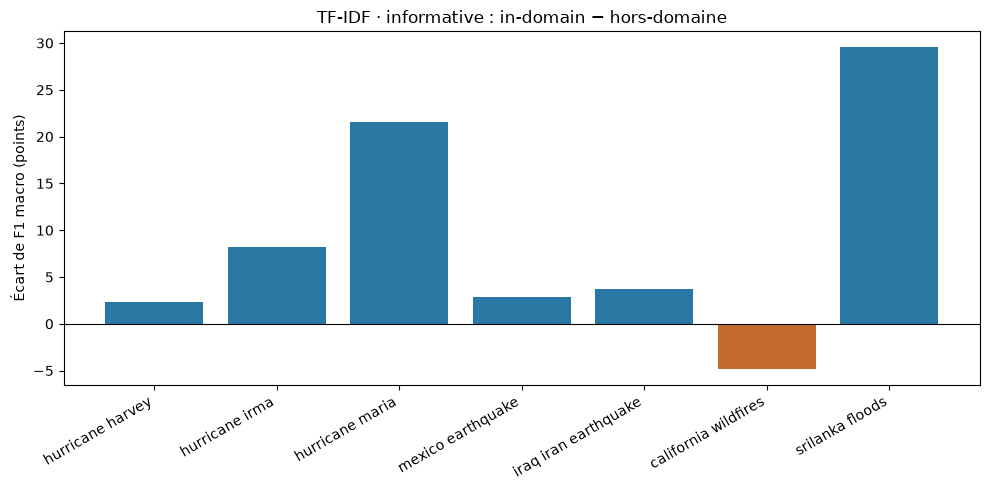

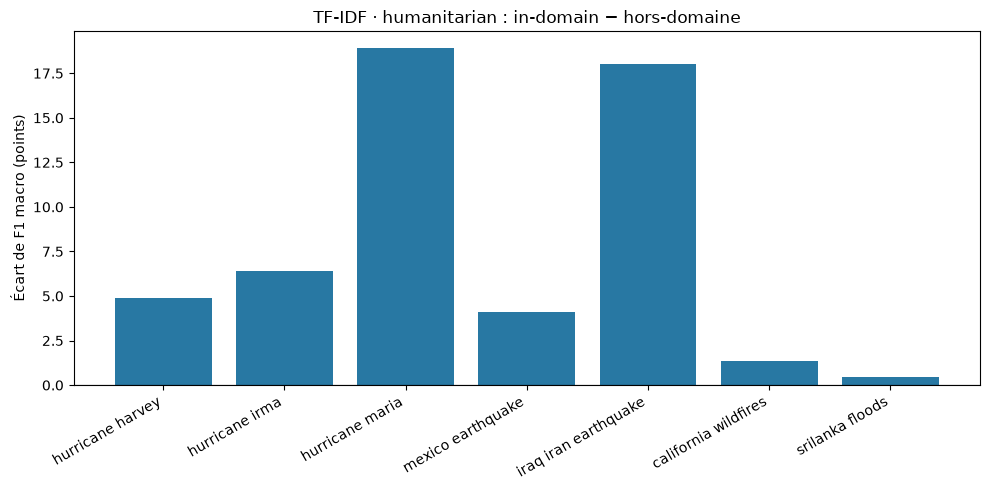

14 expériences complètes ; 42 évaluations ; sources, splits et protocole A inchangés.


In [8]:
expected_folds = {(task, event) for task in TASKS for event in EVENTS}
assert completed == started == expected_folds
assert len(validation_rows) == 70 and len(summary_rows) == 14 and len(artifacts) == 42
summary = pd.DataFrame(summary_rows)
summary.to_csv(TABLE_DIR / 'tfidf_B_summary.csv', index=False)
pd.DataFrame(validation_rows).to_csv(TABLE_DIR / 'tfidf_B_validation.csv', index=False)
pd.DataFrame(per_class_rows).to_csv(TABLE_DIR / 'tfidf_B_per_class.csv', index=False)
(TABLE_DIR / 'tfidf_B_artifacts.json').write_text(json.dumps(artifacts, indent=2) + '\n')
for relative, expected in protected_hashes.items():
    assert hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() == expected, relative
for artifact in artifacts:
    p = pd.read_csv(ROOT / artifact['predictions'], dtype=str, keep_default_na=False)
    m = json.loads((ROOT / artifact['metrics']).read_text())
    assert len(p) == m['n_samples']
    assert np.asarray(m['confusion_matrix']).sum() == len(p)
    assert m['bootstrap']['n_resamples'] == 1000 and m['bootstrap']['seed'] == 42
    assert not p.duplicated(['tweet_id', 'image_id']).any()
    proba = p[[f'proba_{label}' for label in LABELS[artifact['task']]]].to_numpy(float)
    assert np.allclose(proba.sum(axis=1), 1)
    # Une seule inférence par population hors-domaine ; les scores sont relus.
    assert np.array_equal(np.asarray(LABELS[artifact['task']])[proba.argmax(axis=1)], p['y_pred'])
    matrix_table = pd.read_csv(TABLE_DIR / 'tfidf_B_confusion_matrices' / artifact['regime'] /
                              f'{artifact["task"]}_tfidf_B_{artifact["event_name"]}.csv', index_col=0)
    assert matrix_table.to_numpy().tolist() == m['confusion_matrix']
checks = dict(status='passed', completed_experiments=14, trained_C_candidates=70,
              prediction_files=42, metrics_files=42, confusion_figures=42,
              same_test_population=True, target_excluded_from_train_dev=True,
              A_outputs_and_sources_unchanged=True, protected_sha256=protected_hashes,
              all_target_policy='original pairs, not distinct tweets',
              interval_policy='1000 ordinary paired bootstrap draws; seed42; fixed task labels; no gap CI')
(TABLE_DIR / 'tfidf_B_execution_checks.json').write_text(json.dumps(checks, indent=2) + '\n')
display(summary[['task', 'event_name', 'C', 'f1_macro_dev', 'f1_macro_in_domain',
                 'f1_macro_out_of_domain', 'generalization_gap', 'f1_macro_all_target']])
for task in TASKS:
    table = summary.loc[summary['task'].eq(task)]
    x = np.arange(len(table))
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(x, 100*table['generalization_gap'], color=['#2878a3' if gap >= 0 else '#c36a30'
                                                   for gap in table['generalization_gap']])
    ax.axhline(0, color='black', linewidth=.8)
    ax.set(xticks=x, xticklabels=[e.replace('_', ' ') for e in table['event_name']],
           ylabel='Écart de F1 macro (points)', title=f'TF-IDF · {task} : in-domain − hors-domaine')
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f'{task}_tfidf_B_generalization_gap.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
print('14 expériences complètes ; 42 évaluations ; sources, splits et protocole A inchangés.')

## 8. Rapport généré depuis les résultats enregistrés

In [9]:
lines = ['# TF-IDF — rapport du protocole B', '',
         'Deux tâches × sept événements : 14 expériences hors-domaine réellement entraînées. Seed 42.', '',
         '## Méthode et populations', '',
         'Tous les splits proviennent de get_split(task, "B", event, text_only=True). Aucun filtrage manuel des données. '
         'Le TF-IDF (unigrammes/bigrammes, défauts sklearn) apprend son vocabulaire et son IDF sur le train sans cible. '
         'Régression logistique L2 balanced, lbfgs, max_iter=2000, tol=1e-4, random_state=42, un thread. '
         'Grille C=[0.01,0.1,1,10,100] ; maximum de F1 macro dev, égalités exactes au plus petit C. '
         'Les configurations sont écrites avant prédiction cible ; aucun refit train+dev. Aucune non-convergence.', '',
         'Le modèle A n’est pas réentraîné ni réexécuté : seuls ses CSV existants sont restreints à l’événement et alignés '
         'sur le test B par tweet_id, image_id, event_name et y_true. Les prédictions et probabilités numériques sont conservées exactement. '
         'Les fichiers A restent inchangés, contrôle SHA-256.', '',
         '**test_all_target conserve toutes les paires tweet-image**, y compris les images multiples des tweets du train cible. '
         'text_only=True ne déduplique que le train d’apprentissage. C’est la population définie par les modules partagés et '
         'l’unité paire du projet. Le score complémentaire est pondéré par les paires, pas par les tweets distincts. '
         'Son bootstrap ordinaire ne corrige pas la corrélation entre les images d’un même tweet. Aucun changement des modules partagés.', '',
         '## Effectifs par tâche et événement', '',
         '| Tâche | Événement | Train textes | Dev | Test officiel | Complément paires | Complément tweets |',
         '|---|---|---:|---:|---:|---:|---:|']
for row in summary_rows:
    task, event = row['task'], row['event_name']
    s = folds[task, event]
    lines.append(f'| {task} | {event} | {len(s["train"])} | {len(s["dev"])} | {len(s["test"])} | '
                 f'{row["n_all_target_pairs"]} | {row["n_all_target_tweets"]} |')
lines += ['', '## Résultats sur les mêmes lignes du test officiel', '',
          'Scores sur [0,1] ; IC 95 % du F1 macro entre crochets. Gap = F1 macro A − F1 macro hors-domaine. '
          'Les IC individuels ne sont pas des IC du gap.', '',
          '| Tâche | Événement | C | F1 dev | F1 A [IC95] | F1 hors-domaine [IC95] | Gap | F1 pondéré hors-domaine | Accuracy hors-domaine |',
          '|---|---|---:|---:|---|---|---:|---:|---:|']
for r in summary_rows:
    def interval(regime):
        return f'[{r[f"f1_macro_{regime}_ci95_lower"]:.4f}, {r[f"f1_macro_{regime}_ci95_upper"]:.4f}]'
    lines.append(f'| {r["task"]} | {r["event_name"]} | {r["C"]:g} | {r["f1_macro_dev"]:.4f} | '
                 f'{r["f1_macro_in_domain"]:.4f} {interval("in_domain")} | '
                 f'{r["f1_macro_out_of_domain"]:.4f} {interval("out_of_domain")} | '
                 f'{r["generalization_gap"]:+.4f} | {r["f1_weighted_out_of_domain"]:.4f} | {r["accuracy_out_of_domain"]:.4f} |')
lines += ['', '## Score complémentaire sur toutes les paires cibles', '',
          'Ce tableau est distinct de la comparaison A/B ; ses populations incluent des tweets issus du train et dev officiels, '
          'jamais vus par le modèle hors-domaine. Le test officiel est inclus dans ce complément : les deux scores ne sont pas indépendants.', '',
          '| Tâche | Événement | F1 macro complément [IC95] |', '|---|---|---|']
for r in summary_rows:
    lines.append(f'| {r["task"]} | {r["event_name"]} | {r["f1_macro_all_target"]:.4f} '
                 f'[{r["f1_macro_all_target_ci95_lower"]:.4f}, {r["f1_macro_all_target_ci95_upper"]:.4f}] |')
lines += ['', '## Métriques, limites et livrables', '',
          'Toutes les métriques passent par src/evaluate.py. IC95 : 1000 bootstrap percentiles ordinaires, seed42. '
          'Les classes sont fixes pour chaque tâche, même lorsqu’une classe est absente d’un événement/tirage ; '
          'division par zéro = 0. Le support et les scores par classe sont enregistrés dans chaque JSON et dans '
          'results/tables/tfidf_B_per_class.csv. Les faibles supports, surtout affected_individuals, limitent la stabilité des F1 macro. '
          'Les IC ne représentent pas la variabilité entre seeds. Un gap négatif ne prouve pas une supériorité générale du modèle hors-domaine. '
          'Les événements sont comparés séparément, aucune moyenne non pondérée n’est présentée comme score global.', '',
          'Les sélections à la borne C=100 sont conservées ; aucune extension de grille après consultation du test.', '',
          '- Notebook exécuté : notebooks/02b_tfidf_protocol_b.ipynb.',
          '- Prédictions hors-domaine : results/predictions/{task}_tfidf_B_{event}.csv.',
          '- Prédictions A réutilisées : results/predictions/in_domain/{task}_tfidf_B_{event}.csv.',
          '- Complément : results/predictions/all_target/{task}_tfidf_B_{event}.csv.',
          '- JSON correspondants sous results/metrics/, avec les mêmes sous-dossiers.',
          '- Matrices PNG : figures/tfidf_B/{in_domain,out_of_domain,all_target}/ ; matrices CSV : results/tables/tfidf_B_confusion_matrices/.',
          '- Tableaux : tfidf_B_summary.csv, tfidf_B_validation.csv (70 candidats), tfidf_B_population_counts.csv, tfidf_B_per_class.csv.',
          '- Configurations verrouillées : results/tables/tfidf_B_configs/ ; inventaire : tfidf_B_artifacts.json ; contrôles : tfidf_B_execution_checks.json.',
          '- Graphiques des gaps : figures/tfidf_B/{task}_tfidf_B_generalization_gap.png.', '',
          'Contrôles intégrés : 14 folds exécutés, cible absente du train/dev, aucun tweet cible vu en apprentissage, '
          'populations A/B exactes, probabilités A conservées, 42 CSV/JSON et matrices cohérents, empreintes A/sources/splits inchangées. '
          'Les tests automatiques complémentaires et la vérification d’exécution du notebook sont consignés dans tfidf_B_final_checks.json.', '',
          'Pour reproduire : kernel .venv vierge puis Run All. Les sorties B sont réécrites dans leurs chemins propres ; '
          'aucun résultat A, split ou fichier de préparation n’est modifié. Aucun BERTweet, ViT ou CLIP n’est lancé.', '']
(REPORT_DIR / 'tfidf_protocol_b_report.md').write_text('\n'.join(lines), encoding='utf-8')
print('Rapport : reports/tfidf_protocol_b_report.md')

Rapport : reports/tfidf_protocol_b_report.md
